# 03 — Data Preparation (D1) · Deep EDA & Feature Engineering (D2)

**Project:** Booking Cancellation Decision Support System — City Hotel, Lisbon (BA Advanced, Group 2)

| Stage | Task | Deliverable |
|---|---|---|
| **D1** | Validate and standardise the cleaned real data and the synthetic tables, then integrate them at booking level | `data/processed/bookings_prepared.csv` + cleaning log (Section 1.6) |
| **D2** | Deep EDA: relationships, interactions, associations, drift, synthetic sanity checks | EDA findings (Section 2.9) |
| **D2** | Split into two populations (individual vs group/block), time-aware feature sets (`booking_time` / `pre_arrival`), time-based split | `data/processed/modeling_dataset.csv` (with `population`) + feature lists per population in `config/column_groups.json` + `docs/feature_availability.csv` |

**Inputs:** `data/processed/bookings_city_clean.csv` (notebook 01) · `data/synthetic/*.csv` (notebook 02) · `config/column_groups.json` · `config/assumptions.yaml`

> **Rules carried over:** synthetic columns get the prefix `syn_` and are **never model features**. Ops-only columns (`reservation_status*`, `assigned_room_type`, `country`, …) are never features. Every statistic used to build a feature (medians, top-N lists) is computed on the **training period only**.

## 0. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
while not (ROOT / "hotel_bookings.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, SYN, CFG = ROOT / "data" / "processed", ROOT / "data" / "synthetic", ROOT / "config"
GROUPS = json.load(open(CFG / "column_groups.json"))
A = yaml.safe_load(open(CFG / "assumptions.yaml"))
SEED = A["meta"]["random_seed"]

DATES = ["arrival_date", "booking_date", "reservation_status_date"]
bk = pd.read_csv(PROC / "bookings_city_clean.csv", parse_dates=DATES, keep_default_na=False, na_values=[""])
cx_contact = pd.read_csv(SYN / "cx_contact.csv", parse_dates=["contact_date"])
cx_feedback = pd.read_csv(SYN / "cx_feedback.csv")
fin = pd.read_csv(SYN / "fin_booking.csv")
ops = pd.read_csv(SYN / "ops_inventory_daily.csv", parse_dates=["stay_date"], keep_default_na=False, na_values=[""])
rooms = pd.read_csv(SYN / "dim_room_type.csv")
for name, t in [("bookings", bk), ("cx_contact", cx_contact), ("cx_feedback", cx_feedback),
                ("fin_booking", fin), ("ops_inventory_daily", ops), ("dim_room_type", rooms)]:
    print(f"{name:20s} {t.shape[0]:>7,} rows x {t.shape[1]:>2} cols")

bookings              79,330 rows x 39 cols
cx_contact            79,330 rows x  6 cols
cx_feedback           79,330 rows x  5 cols
fin_booking           79,330 rows x  7 cols
ops_inventory_daily    7,227 rows x  9 cols
dim_room_type              9 rows x  4 cols


# D1 — Clean and standardise based on the audit

Notebook 01 already cleaned the **real** data (missing values, duplicates, formats, outliers, logic) and documented it in its Section 3.6. D1 does **not** repeat that. It:
1. re-validates the real table against the audit rules (so nothing regressed),
2. validates the synthetic tables (keys, domains, ranges, conditional nulls),
3. standardises types and names across tables,
4. integrates everything into **one booking-level prepared dataset**, adding booking-level aggregates from the date × room-type table,
5. logs every step in the cleaning log (1.6).

In [2]:
log = []
def step(area, rule, n_rows, action, status="ok"):
    log.append({"area": area, "rule": rule, "n_rows": int(n_rows), "action": action, "status": status})

### 1.1 Re-validate the real bookings table against the audit

In [3]:
expected = set(GROUPS["id_target"] + GROUPS["ops_only_cols"] + GROUPS["nb01_candidate_columns"])
assert set(bk.columns) == expected, set(bk.columns) ^ expected
step("real", "columns match config/column_groups.json", len(bk.columns), "none")

assert bk.booking_id.is_unique and bk.booking_id.min() == 1 and bk.booking_id.max() == len(bk)
step("real", "booking_id unique, 1..N", len(bk), "none")

checks = {
    "no NaN except adr_clean (data error)": bk.drop(columns="adr_clean").isna().sum().sum() == 0,
    "children / country / agent_id filled": bk[["children", "country", "agent_id"]].isna().sum().sum() == 0,
    "no 'Undefined' meal": (bk.meal != "Undefined").all(),
    "country codes 3 letters": bk.country.str.len().eq(3).all(),
    "adr_clean <= 1000": (bk.adr_clean.dropna() <= 1000).all(),
    "is_canceled consistent with status": (bk.is_canceled.eq(1) == bk.reservation_status.isin(["Canceled", "No-Show"])).all(),
    "booking_date = arrival - lead_time": (bk.booking_date == bk.arrival_date - pd.to_timedelta(bk.lead_time, unit="D")).all(),
    "total_nights = weekend + week": (bk.total_nights == bk.stays_in_weekend_nights + bk.stays_in_week_nights).all(),
    "gross_value = adr_clean x nights": np.allclose(bk.gross_value, (bk.adr_clean.clip(lower=0) * bk.total_nights).fillna(0), atol=0.01),
}
for k, v in checks.items():
    step("real", k, len(bk), "none" if v else "FAILED", "ok" if v else "FAIL")
assert all(checks.values())
pd.Series(checks, name="passed").to_frame()

,passed
no NaN except adr_clean (data error),True
children / country / agent_id filled,True
no 'Undefined' meal,True
country codes 3 letters,True
adr_clean <= 1000,True
is_canceled consistent with status,True
booking_date = arrival - lead_time,True
total_nights = weekend + week,True
gross_value = adr_clean x nights,True


### 1.2 Validate the synthetic tables

In [4]:
ids = set(bk.booking_id)
for name, t in [("cx_contact", cx_contact), ("cx_feedback", cx_feedback), ("fin_booking", fin)]:
    ok = t.booking_id.is_unique and set(t.booking_id) == ids
    step("synthetic", f"{name}: 1:1 with bookings", len(t), "none" if ok else "FAILED", "ok" if ok else "FAIL")
    assert ok
    assert t.is_synthetic.all()

def synthetic_checks(bk, cx_contact, cx_feedback, fin, ops, rooms):
    """Domain and conditional-null checks. Every booking-level table is aligned on booking_id
    (never on row position), so the result does not depend on the order of the files."""
    st = bk.set_index("booking_id")[["reservation_status", "is_canceled", "booking_date", "arrival_date", "reservation_status_date"]]
    cxc = cx_contact.set_index("booking_id").reindex(st.index)
    cxf = cx_feedback.set_index("booking_id").reindex(st.index)
    fn = fin.set_index("booking_id").reindex(st.index)
    is_co, is_canc, is_cancel_any = st.reservation_status.eq("Check-Out"), st.reservation_status.eq("Canceled"), st.is_canceled.eq(1)
    contacted = cxc.contact_attempted.astype(bool)
    cdate = pd.to_datetime(cxc.contact_date)
    return {
        # domains
        "contact_channel in {email, sms, phone}": cxc.contact_channel.dropna().isin(["email", "sms", "phone"]).all(),
        "customer_response in domain": cxc.customer_response.dropna().isin(["confirmed", "requested_change", "no_response"]).all(),
        "satisfaction 1..5": cxf.satisfaction_score.dropna().between(1, 5).all(),
        "commission rate in [0, 1]": fn.channel_commission_rate.between(0, 1).all(),
        "costs, revenue and resold nights >= 0": (fn[["room_cost_per_night", "cancellation_handling_cost", "rebooking_revenue",
                                                     "rebooked_room_nights"]].fillna(0) >= 0).all().all(),
        # conditional nulls, by booking_id
        "channel/date/response only if contacted": (cxc.contact_channel.notna().eq(contacted) & cdate.notna().eq(contacted)
                                                    & cxc.customer_response.notna().eq(contacted)).all(),
        "contact date between booking and arrival": ((cdate >= st.booking_date) & (cdate <= st.arrival_date))[contacted].all(),
        "no contact after a cancellation": not (is_canc & contacted & (cdate > st.reservation_status_date)).any(),
        "satisfaction only for Check-Out": cxf.satisfaction_score.notna().eq(is_co).all(),
        "reason only for Canceled": cxf.cancellation_reason_category.notna().eq(is_canc).all(),
        "handling cost only if is_canceled": fn.cancellation_handling_cost.notna().eq(is_cancel_any).all(),
        "rebooking revenue / nights only for Canceled": (fn.rebooking_revenue.notna().eq(is_canc)
                                                         & fn.rebooked_room_nights.notna().eq(is_canc)).all(),
        # ops
        "ops key (stay_date, room_type) unique": not ops.duplicated(["stay_date", "room_type"]).any(),
        "ops room types in dim_room_type": ops.room_type.isin(rooms.room_type).all(),
        "rooms_sold <= available_rooms": (ops.rooms_sold <= ops.available_rooms).all(),
        "resold <= min(cancelled, sold)": (ops.resold_after_cancellation <= np.minimum(ops.rooms_cancelled, ops.rooms_sold)).all(),
        "booking room types in dim_room_type": bk.reserved_room_type.isin(rooms.room_type).all() and bk.assigned_room_type.isin(rooms.room_type).all(),
    }

syn_checks = synthetic_checks(bk, cx_contact, cx_feedback, fin, ops, rooms)
for k, v in syn_checks.items():
    step("synthetic", k, len(bk) if "ops" not in k else len(ops), "none" if v else "FAILED", "ok" if v else "FAIL")
assert all(syn_checks.values())

# Order-independence test: shuffling the synthetic tables must not change any result
shuffled = [t.sample(frac=1, random_state=SEED) for t in (cx_contact, cx_feedback, fin)]
same = synthetic_checks(bk, *shuffled, ops, rooms) == syn_checks
step("synthetic", "checks unchanged after shuffling the synthetic tables (ID-aligned)", len(bk), "none" if same else "FAILED", "ok" if same else "FAIL")
assert same
pd.Series(syn_checks, name="passed").to_frame()


,passed
"contact_channel in {email, sms, phone}",True
customer_response in domain,True
satisfaction 1..5,True
"commission rate in [0, 1]",True
"costs, revenue and resold nights >= 0",True
channel/date/response only if contacted,True
contact date between booking and arrival,True
no contact after a cancellation,True
satisfaction only for Check-Out,True
reason only for Canceled,True


### 1.3 Standardise types and names

In [5]:
# booleans and integers
cx_contact["contact_attempted"] = cx_contact.contact_attempted.astype(bool)
cx_feedback["satisfaction_score"] = cx_feedback.satisfaction_score.astype("Int64")
bk["exclude_from_model"] = bk.exclude_from_model.astype(bool)
step("standardise", "booleans / nullable integers", len(bk), "cast")

# synthetic columns -> 'syn_' prefix so they can never be mistaken for real data
syn_tables = {"cx_contact": cx_contact, "cx_feedback": cx_feedback, "fin_booking": fin}
renamed = {}
for name, t in syn_tables.items():
    cols = [c for c in t.columns if c not in ("booking_id", "is_synthetic")]
    renamed[name] = {c: f"syn_{c}" for c in cols}
    syn_tables[name] = t.drop(columns="is_synthetic").rename(columns=renamed[name])
step("standardise", "prefix synthetic columns with syn_", sum(len(v) for v in renamed.values()), "rename")

# categorical dtypes for low-cardinality text
cat_cols = ["reservation_status", "meal", "country", "market_segment", "distribution_channel",
            "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type", "arrival_dow", "agent_id"]
bk[cat_cols] = bk[cat_cols].astype("category")
step("standardise", "categorical dtypes", len(cat_cols), "cast")
pd.DataFrame({t: list(m.values()) for t, m in renamed.items()}.items(), columns=["table", "synthetic columns"])

,table,synthetic columns
0,cx_contact,"[syn_contact_attempted, syn_contact_channel, s..."
1,cx_feedback,"[syn_satisfaction_score, syn_cancellation_reas..."
2,fin_booking,"[syn_room_cost_per_night, syn_channel_commissi..."


### 1.4 Booking-level aggregates from the date × room-type table

Ops data is at stay-date × room-type level. Two booking-level views are added:
- `drv_arrival_occupancy`: occupancy of the reserved room type on the arrival date. This is **realised** occupancy (it includes other guests' final outcomes), so it is **ops-only** and never a feature.
- `drv_otb_rooms_at_booking`: earlier bookings for the **same arrival date** (all room types) that were still active on this booking's booking date. It is reconstructed **as of the booking date** from other bookings' booking and cancellation dates, so it uses no information from after that day. Limits: day granularity (within-day order unknown), dates come from the final snapshot, and it counts same-arrival bookings, **not** total on-the-books room-nights including stay-overs. Treated as a secondary demand-pressure feature with these caveats.

In [6]:
occ = ops.set_index(["stay_date", "room_type"]).occupancy_rate
bk["drv_arrival_occupancy"] = occ.reindex(pd.MultiIndex.from_arrays(
    [bk.arrival_date, bk.reserved_room_type.astype(str)])).values

def otb_at_booking(g):
    # for each booking: earlier bookings (booking_date < own) still active at own booking_date
    b = g.booking_date.values.astype("datetime64[D]")
    end = np.where(g.reservation_status.astype(str).values == "Check-Out",
                   np.datetime64("2100-01-01"), g.reservation_status_date.values.astype("datetime64[D]"))
    out = np.empty(len(g), dtype=int)
    for i in range(len(g)):
        out[i] = np.sum((b < b[i]) & (end > b[i]))
    return pd.Series(out, index=g.index)

bk["drv_otb_rooms_at_booking"] = (bk.groupby("arrival_date", group_keys=False)[["booking_date", "reservation_status", "reservation_status_date"]]
                                    .apply(otb_at_booking))
step("integrate", "add drv_arrival_occupancy (ops-only)", bk.drv_arrival_occupancy.notna().sum(), "join ops on arrival_date x reserved_room_type")
step("integrate", "add drv_otb_rooms_at_booking (pre-arrival demand)", len(bk), "computed per arrival_date")
bk[["drv_arrival_occupancy", "drv_otb_rooms_at_booking"]].describe().T

,count,mean,std,min,25%,50%,75%,max
drv_arrival_occupancy,"79,320.000",0.814,0.200,0.000,0.753,0.890,0.947,1.000
drv_otb_rooms_at_booking,"79,330.000",33.485,28.506,0.000,9.000,29.000,52.000,210.000


### 1.5 Integrate into the prepared dataset

In [7]:
prep = bk.copy()
for name, t in syn_tables.items():
    prep = prep.merge(t, on="booking_id", how="left", validate="1:1")
assert len(prep) == len(bk)

# business metric derived from real + synthetic (marked syn_ because it depends on simulated inputs)
prep["syn_net_booking_value"] = (prep.gross_value * (1 - prep.syn_channel_commission_rate)
                                 - prep.syn_room_cost_per_night * prep.total_nights).round(2)
step("integrate", "join cx_contact, cx_feedback, fin_booking (1:1)", len(prep), "left join on booking_id, validate 1:1")
step("integrate", "add syn_net_booking_value", len(prep), "gross x (1 - commission) - cost x nights")

prep.to_csv(PROC / "bookings_prepared.csv", index=False, date_format="%Y-%m-%d")
print("Saved:", PROC / "bookings_prepared.csv", prep.shape)
prep.head(3).T

Saved: C:\Users\ADMIN\Desktop\AAA\BA-Advance-Project---Group-2-main\data\processed\bookings_prepared.csv (79330, 54)


,0,1,2
booking_id,1,2,3
is_canceled,0,1,1
reservation_status,Check-Out,Canceled,Canceled
reservation_status_date,2015-07-03 00:00:00,2015-07-01 00:00:00,2015-04-30 00:00:00
booking_date,2015-06-25 00:00:00,2015-04-04 00:00:00,2015-04-27 00:00:00
arrival_date,2015-07-01 00:00:00,2015-07-01 00:00:00,2015-07-01 00:00:00
lead_time,6,88,65
stays_in_weekend_nights,0,0,0
stays_in_week_nights,2,4,4
adults,1,2,1


### 1.6 Cleaning log

The real-data cleaning rules (missing values, duplicates, formatting, outliers, logic) are in **notebook 01, Section 3.6**. The table below logs the D1 validation, standardisation and integration steps.

In [8]:
cleaning_log = pd.DataFrame(log)
print(f"{len(cleaning_log)} steps | failures: {(cleaning_log.status != 'ok').sum()}")
cleaning_log

39 steps | failures: 0


,area,rule,n_rows,action,status
0,real,columns match config/column_groups.json,39,none,ok
1,real,"booking_id unique, 1..N",79330,none,ok
2,real,no NaN except adr_clean (data error),79330,none,ok
3,real,children / country / agent_id filled,79330,none,ok
4,real,no 'Undefined' meal,79330,none,ok
5,real,country codes 3 letters,79330,none,ok
6,real,adr_clean <= 1000,79330,none,ok
7,real,is_canceled consistent with status,79330,none,ok
8,real,booking_date = arrival - lead_time,79330,none,ok
9,real,total_nights = weekend + week,79330,none,ok


# D2 — Deep EDA, relationships and feature engineering

EDA uses the modelling population: `exclude_from_model == False`. The time split from README §6.2 is defined first, so that drift can be checked and feature statistics computed on the training period only.

> **Disclosure (test-period labels).** The exploratory analyses in Sections 2.0–2.3 and 2.5–2.8 (except the mutual-information ranking) use **all** eligible bookings, including the 2017 test period, and therefore looked at 2017 outcomes. Only the mutual-information ranking (2.4) and every statistic used to *build* a feature (ADR reference, top agents) are fitted on the training period; the drift check (2.5) compares train with test by design. The 2017 test set is therefore a **partially explored holdout**, not an untouched one. Feature lists were not tuned on test-set model performance; F must report results with this caveat and choose thresholds on a validation period inside the training years.

In [9]:
df = prep[~prep.exclude_from_model].copy()
TRAIN_END = pd.Timestamp("2016-12-31")
df["split"] = np.where(df.arrival_date <= TRAIN_END, "train", "test")
y = df.is_canceled
print(df.split.value_counts().to_string())
print(df.groupby("split").is_canceled.mean().round(3).to_string())

split
train    51496
test     27396
split
test    0.426
train   0.415


### 2.0 Two populations: individual guests vs group / block bookings

The dataset has no explicit "group" field, so `group_block` is an **inferred proxy**, defined as **any** of:
- `market_segment == "Groups"`,
- `deposit_type == "Non Refund"` (almost all cancel, mostly in batches, which is consistent with tour-operator allotments; this is inferred, not verified),
- `dup_group_size >= 5`: at least 5 bookings share the same **reservation attributes in the extract** (retrospective block-size proxy, see notebook 01, Section 3.2).

Everything else is `individual`. The two populations need **different decisions**. Individual guests get follow-up (email, reminder, call). Group blocks need release deadlines, staged deposits, capacity reallocation and controlled overbooking. They are therefore modelled separately, and the individual-guest model is the one whose accuracy is reported as the headline figure.

> **Limits of the proxy.** It is not a verified group/allotment label: `customer_type` is not used, so some `Group` / `Contract` bookings stay in `individual` (Section 2.0.1). The `dup_group_size` part uses attribute values from the near-arrival snapshot and counts the whole booking-day cohort, so its availability at booking entry is not verified. Section 2.0.1 tests how much the populations move under alternative rules.

In [10]:
df["population"] = np.where(df.market_segment.astype(str).eq("Groups")
                            | df.deposit_type.astype(str).eq("Non Refund")
                            | (df.dup_group_size >= 5), "group_block", "individual")
pop = (df.groupby(["population", "split"]).agg(bookings=("booking_id", "size"), cancel_rate=("is_canceled", "mean"),
                                               room_nights=("total_nights", "sum"), gross_value=("gross_value", "sum"))
         .round(3))
display(pop)
pd.crosstab(df.population, df.deposit_type, normalize="index").round(3)

bookings  cancel_rate  room_nights    gross_value
population  split                                                   
group_block test       6997        0.667        18438  1,919,763.650
            train     19219        0.642        48857  4,344,897.520
individual  test      20399        0.344        67088  8,275,883.100
            train     32277        0.280       101104 10,723,396.110

deposit_type,No Deposit,Non Refund,Refundable
population,,,
group_block,0.509,0.491,0.000
individual,1.000,0.000,0.000


#### 2.0.1 How robust is the population proxy?

In [11]:
# (a) customer_type inside each population
ct = df.customer_type.astype(str)
display(pd.crosstab(df.population, ct, margins=True))
ind = df[df.population == "individual"]
print(f"In individual: customer_type Group = {(ind.customer_type.astype(str) == 'Group').sum():,}, "
      f"Contract = {(ind.customer_type.astype(str) == 'Contract').sum():,}")
display(ind.groupby(ind.customer_type.astype(str)).agg(bookings=("booking_id", "size"), cancel_rate=("is_canceled", "mean"),
                                                         median_dup_group_size=("dup_group_size", "median")).round(3))

# (b) sensitivity of the population rule
seg_groups = df.market_segment.astype(str).eq("Groups")
non_refund = df.deposit_type.astype(str).eq("Non Refund")
rules = {
    "A (used): Groups | Non Refund | dup>=5": seg_groups | non_refund | (df.dup_group_size >= 5),
    "B: Groups | Non Refund (no block size)": seg_groups | non_refund,
    "C: Groups | Non Refund | dup>=3": seg_groups | non_refund | (df.dup_group_size >= 3),
    "D: Groups | Non Refund | dup>=10": seg_groups | non_refund | (df.dup_group_size >= 10),
    "E: A | customer_type in {Group, Contract}": seg_groups | non_refund | (df.dup_group_size >= 5) | ct.isin(["Group", "Contract"]),
}
base_rule = rules["A (used): Groups | Non Refund | dup>=5"]
sens = []
for name, g_mask in rules.items():
    r_ = {"rule": name, "group_block": int(g_mask.sum()), "individual": int((~g_mask).sum()),
          "same_label_as_A": float((g_mask == base_rule).mean())}
    for sp in ["train", "test"]:
        m_ = ~g_mask & df.split.eq(sp)
        r_[f"individual_cancel_{sp}"] = df.loc[m_, "is_canceled"].mean()
        r_[f"group_cancel_{sp}"] = df.loc[g_mask & df.split.eq(sp), "is_canceled"].mean()
    sens.append(r_)
pd.DataFrame(sens).set_index("rule").round(3)


customer_type,Contract,Group,Transient,Transient-Party,All
population,,,,,
group_block,737,9,12817,12653,26216
individual,1552,281,46220,4623,52676
All,2289,290,59037,17276,78892


In individual: customer_type Group = 281, Contract = 1,552


,bookings,cancel_rate,median_dup_group_size
customer_type,,,
Contract,1552,0.249,1.000
Group,281,0.085,1.000
Transient,46220,0.323,1.000
Transient-Party,4623,0.156,2.000


,group_block,individual,same_label_as_A,individual_cancel_train,group_cancel_train,individual_cancel_test,group_cancel_test
rule,,,,,,,
A (used): Groups | Non Refund | dup>=5,26216,52676,1.000,0.280,0.642,0.344,0.667
B: Groups | Non Refund (no block size),19162,59730,0.911,0.283,0.786,0.344,0.742
C: Groups | Non Refund | dup>=3,29543,49349,0.958,0.278,0.608,0.339,0.632
D: Groups | Non Refund | dup>=10,24197,54695,0.974,0.283,0.664,0.348,0.685
"E: A | customer_type in {Group, Contract}",28049,50843,0.977,0.283,0.608,0.345,0.658


**Reading the sensitivity table.** Rule A is the one used. Dropping the block-size part (rule B), moving its threshold (C, D) or adding `customer_type` `Group` / `Contract` (E) relabels 2–9% of bookings, but the **individual** cancellation rate barely moves (about 28% train, 34% test under every rule). The `group_block` rate is more sensitive (61–79% train): the core (segment Groups or Non Refund) cancels at about 77%, while bookings that enter only through block size or `customer_type` cancel at roughly 22–39%, so the rule mostly decides how diluted the group population is. F1 should report the headline individual metrics for rule A **and** at least one alternative rule, so the result is not an artefact of the proxy. The 281 `Group` and 1,552 `Contract` bookings in `individual` are bookings whose segment is not `Groups`, whose deposit is not Non Refund and whose identical-attribute cohort is smaller than 5: `customer_type` describes the contract type of the booking, while the proxy targets block / allotment behaviour, so the two do not have to coincide.

### 2.1 Numeric features: distributions by outcome and correlations

In [12]:
num = ["lead_time", "total_nights", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
       "total_guests", "adr_clean", "previous_cancellations", "previous_bookings_not_canceled",
       "total_of_special_requests", "booking_changes", "days_in_waiting_list", "dup_group_size",
       "drv_otb_rooms_at_booking", "arrival_month_num", "arrival_week_iso"]
summary = df.groupby("is_canceled")[num].median().T.rename(columns={0: "median_stayed", 1: "median_cancelled"})
summary["spearman_with_target"] = [df[c].corr(y, method="spearman") for c in num]
summary.sort_values("spearman_with_target", key=abs, ascending=False)

is_canceled,median_stayed,median_cancelled,spearman_with_target
total_of_special_requests,1.000,0.000,-0.326
dup_group_size,1.000,4.000,0.323
lead_time,50.000,115.000,0.323
previous_cancellations,0.000,0.000,0.280
drv_otb_rooms_at_booking,35.000,20.000,-0.219
booking_changes,0.000,0.000,-0.195
days_in_waiting_list,0.000,0.000,0.112
previous_bookings_not_canceled,0.000,0.000,-0.099
adults,2.000,2.000,0.053
stays_in_week_nights,2.000,2.000,0.042


In [13]:
corr = df[num].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("rho").reset_index().query("abs(rho) >= 0.6").sort_values("rho", key=abs, ascending=False))
pairs  # highly correlated pairs -> keep one for linear models

,level_0,level_1,rho
135,arrival_month_num,arrival_week_iso,0.975
59,adults,total_guests,0.890
17,total_nights,stays_in_week_nights,0.795


### 2.2 Categorical features: association with the target (Cramér's V)

In [14]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b).values
    n = ct.sum(); r, k = ct.shape
    exp = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - exp) ** 2 / exp).sum()
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-9, min(kc - 1, rc - 1)))

cats = ["deposit_type", "market_segment", "distribution_channel", "customer_type", "reserved_room_type",
        "meal", "agent_id", "arrival_dow", "is_repeated_guest", "has_agent", "has_company"]
leaky = ["country", "assigned_room_type"]          # shown for comparison only, never features
cv = pd.Series({c: cramers_v(df[c].astype(str), y) for c in cats + leaky}).sort_values(ascending=False)
cv.to_frame("cramers_v").assign(role=lambda t: np.where(t.index.isin(leaky), "LEAKY (excluded)", "candidate"))

,cramers_v,role
deposit_type,0.518,candidate
country,0.408,LEAKY (excluded)
agent_id,0.389,candidate
market_segment,0.292,candidate
assigned_room_type,0.180,LEAKY (excluded)
distribution_channel,0.173,candidate
customer_type,0.154,candidate
has_company,0.092,candidate
arrival_dow,0.087,candidate
reserved_room_type,0.075,candidate


In [15]:
# Redundancy between categoricals
red = pd.DataFrame([(a, b, cramers_v(df[a].astype(str), df[b].astype(str)))
                    for i, a in enumerate(cats[:5]) for b in cats[i + 1:5]], columns=["a", "b", "cramers_v"])
red.sort_values("cramers_v", ascending=False)

,a,b,cramers_v
4,market_segment,distribution_channel,0.748
0,deposit_type,market_segment,0.406
5,market_segment,customer_type,0.271
6,market_segment,reserved_room_type,0.164
3,deposit_type,reserved_room_type,0.156
9,customer_type,reserved_room_type,0.121
8,distribution_channel,reserved_room_type,0.116
2,deposit_type,customer_type,0.108
1,deposit_type,distribution_channel,0.093
7,distribution_channel,customer_type,0.074


### 2.3 Interactions that matter for decisions

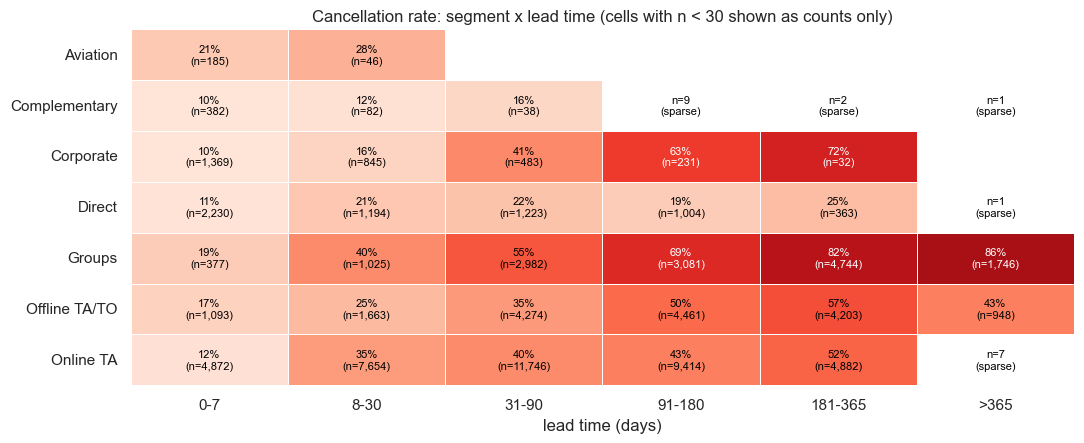

Direct: max rate over bins with n >= 30 = 24.5%


lead_bucket,0-7,8-30,31-90,91-180,181-365,>365
cancel_rate,0.110,0.209,0.223,0.193,0.245,1.000
n,"2,230.000","1,194.000","1,223.000","1,004.000",363.000,1.000


In [16]:
df["lead_bucket"] = pd.cut(df.lead_time, [-1, 7, 30, 90, 180, 365, 1000],
                           labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])
MIN_N = 30   # cells with fewer bookings are shown as counts only, not as rates
seg_df = df[df.market_segment.astype(str) != "Undefined"]
p1 = seg_df.pivot_table(index="market_segment", columns="lead_bucket", values="is_canceled", aggfunc="mean", observed=True)
n1 = (seg_df.pivot_table(index="market_segment", columns="lead_bucket", values="is_canceled", aggfunc="size", observed=True)
            .reindex(index=p1.index, columns=p1.columns).fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(p1.where(n1 >= MIN_N), annot=False, cmap="Reds", vmin=0, vmax=1, cbar=False, linewidths=0.5, linecolor="white", ax=ax)
for i, seg_ in enumerate(p1.index):
    for j, b_ in enumerate(p1.columns):
        n_ = n1.loc[seg_, b_]
        txt = f"{p1.loc[seg_, b_]:.0%}\n(n={n_:,})" if n_ >= MIN_N else (f"n={n_}\n(sparse)" if n_ > 0 else "")
        ax.text(j + 0.5, i + 0.5, txt, ha="center", va="center", fontsize=8,
                color="black" if n_ < MIN_N or p1.loc[seg_, b_] < 0.6 else "white")
ax.set_title(f"Cancellation rate: segment x lead time (cells with n < {MIN_N} shown as counts only)")
ax.set_xlabel("lead time (days)"); ax.set_ylabel(""); ax.grid(False)
plt.tight_layout(); plt.show()
direct = pd.DataFrame({"cancel_rate": p1.loc["Direct"], "n": n1.loc["Direct"]})
print(f"Direct: max rate over bins with n >= {MIN_N} = {direct.loc[direct.n >= MIN_N, 'cancel_rate'].max():.1%}")
direct.T.round(3)


In [17]:
# Seasonality is weaker than lead time / segment
df.groupby("arrival_month_num").is_canceled.mean().round(3).to_frame("cancel_rate").T

arrival_month_num,1,2,3,4,5,6,7,8,9,10,11,12
cancel_rate,0.399,0.385,0.372,0.464,0.446,0.448,0.410,0.402,0.421,0.433,0.385,0.424


In [18]:
# Demand pressure at booking time vs cancellation
df["otb_bucket"] = pd.qcut(df.drv_otb_rooms_at_booking, 5, duplicates="drop")
print("Spearman(otb, lead_time) =", round(df.drv_otb_rooms_at_booking.corr(df.lead_time, method="spearman"), 3))
# within similar lead times, does on-the-books demand still matter?
display(df.groupby("otb_bucket", observed=True).is_canceled.agg(bookings="size", cancel_rate="mean").round(3))
df.pivot_table(index="lead_bucket", columns=pd.qcut(df.drv_otb_rooms_at_booking, 3, labels=["low OTB", "mid OTB", "high OTB"]),
               values="is_canceled", aggfunc="mean", observed=True).round(3)

Spearman(otb, lead_time) = -0.574


,bookings,cancel_rate
otb_bucket,,
"(-0.001, 5.0]",16832,0.636
"(5.0, 21.0]",15350,0.411
"(21.0, 37.0]",15443,0.392
"(37.0, 57.0]",15559,0.323
"(57.0, 210.0]",15708,0.316


drv_otb_rooms_at_booking,low OTB,mid OTB,high OTB
lead_bucket,,,
0-7,0.097,0.104,0.135
8-30,0.266,0.328,0.306
31-90,0.437,0.391,0.384
91-180,0.529,0.450,0.451
181-365,0.658,0.558,0.551
>365,0.703,1.000,NaN


### 2.4 Mutual information: ranking of candidate features (training period)

In [19]:
mi_cols = num + ["deposit_type", "market_segment", "distribution_channel", "customer_type",
                 "reserved_room_type", "meal", "arrival_dow", "is_repeated_guest", "has_agent", "has_company"]
tr = df[df.split == "train"].sample(30000, random_state=SEED)
X = tr[mi_cols].copy()
disc = []
for c in mi_cols:
    if not pd.api.types.is_numeric_dtype(X[c]):
        X[c] = X[c].astype("category").cat.codes; disc.append(True)
    else:
        X[c] = X[c].fillna(X[c].median()); disc.append(c in ["is_repeated_guest", "has_agent", "has_company"])
mi = pd.Series(mutual_info_classif(X, tr.is_canceled, discrete_features=disc, random_state=SEED), index=mi_cols)
mi = mi.sort_values(ascending=False)
mi.to_frame("mutual_info")

,mutual_info
deposit_type,0.176
dup_group_size,0.137
lead_time,0.125
adr_clean,0.099
previous_cancellations,0.083
total_of_special_requests,0.063
drv_otb_rooms_at_booking,0.060
market_segment,0.051
days_in_waiting_list,0.028
booking_changes,0.018


### 2.5 Stability over time: train vs test drift (PSI)

In [20]:
PSI_EPS = 0.5   # additive smoothing on bin / category COUNTS (both periods), so empty cells give a finite PSI

def psi(a, b, bins=10):
    """Population stability index of b (later period) vs a (reference period).
    Numeric (> 10 distinct values): 10 quantile bins of a; b is clipped to a's range.
    Categorical: the UNION of categories of both periods, so categories that appear only in the
    later period (e.g. new agents) count as drift instead of being dropped."""
    a, b = a.dropna(), b.dropna()
    if pd.api.types.is_numeric_dtype(a) and a.nunique() > 10:
        edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
        ca = np.histogram(a, edges)[0]
        cb = np.histogram(b.clip(edges[0], edges[-1]), edges)[0]
    else:
        a, b = a.astype(str), b.astype(str)
        levels = sorted(set(a) | set(b))
        ca = a.value_counts().reindex(levels, fill_value=0).values
        cb = b.value_counts().reindex(levels, fill_value=0).values
    pa = (ca + PSI_EPS) / (ca.sum() + PSI_EPS * len(ca))
    pb = (cb + PSI_EPS) / (cb.sum() + PSI_EPS * len(cb))
    return float(np.sum((pa - pb) * np.log(pa / pb)))

trn, tst = df[df.split == "train"], df[df.split == "test"]
drift_cols = [c for c in mi_cols if c not in ("arrival_month_num", "arrival_week_iso")] + ["agent_id"]
drift = pd.Series({c: psi(trn[c], tst[c]) for c in drift_cols})
drift = drift.sort_values(ascending=False).to_frame("psi")
drift["level"] = pd.cut(drift.psi, [-1, 0.1, 0.25, 10], labels=["stable", "moderate", "significant"])
new_agents = set(tst.agent_id.astype(str)) - set(trn.agent_id.astype(str))
print(f"agent IDs seen only in test: {len(new_agents)} ({tst.agent_id.astype(str).isin(new_agents).mean():.1%} of test bookings)")

# D207: ADR shift, stated with its statistic and periods
adr = df.groupby("split").adr_clean.agg(["median", "mean"]).loc[["train", "test"]]
adr.loc["change"] = adr.loc["test"] / adr.loc["train"] - 1
print("ADR (EUR) train = arrivals Jul-2015..Dec-2016, test = Jan..Aug-2017:")
display(adr.round(4))
drift


agent IDs seen only in test: 40 (5.1% of test bookings)
ADR (EUR) train = arrivals Jul-2015..Dec-2016, test = Jan..Aug-2017:


,median,mean
split,,
train,95.000,99.321
test,110.670,117.959
change,0.165,0.188


,psi,level
agent_id,1.087,significant
adr_clean,0.298,significant
previous_cancellations,0.294,significant
customer_type,0.291,significant
market_segment,0.125,moderate
dup_group_size,0.121,moderate
drv_otb_rooms_at_booking,0.112,moderate
meal,0.068,stable
lead_time,0.064,stable
reserved_room_type,0.053,stable


> PSI < 0.1 = stable, 0.1–0.25 = moderate shift, > 0.25 = significant. Categorical PSI uses the **union** of train and test categories, and both periods get the same additive smoothing (0.5 per bin / category) before the shares are computed. The test period covers only Jan–Aug, so seasonal features shift by design and are excluded from this check; ADR is also seasonal, so part of its shift reflects the Jan–Aug mix, not only price growth.

### 2.6 Revenue and occupancy view (real + **simulated**)

Values marked *simulated* depend on `config/assumptions.yaml`. All money for a cancelled booking is put on **one contribution basis** (room revenue net of channel commission, minus room cost), so nothing is counted twice:

| Component (cancelled bookings only) | Definition |
|---|---|
| `contribution_lost_sim` | `syn_net_booking_value` = gross × (1 − commission) − room cost × nights: what the stay would have contributed |
| `deposit_retained_sim` | gross × `finance.deposit_retained_share` (by deposit type; base case 0, Non Refund tested 0 → 100%) |
| `handling_cost_sim` | `syn_cancellation_handling_cost` |
| `resale_contribution_sim` | resale revenue × (1 − `finance.resale_commission_rate`) − room cost × resold nights: what the replacement sale contributes |
| **`net_loss_proxy_sim`** | contribution lost − deposit retained + handling cost − resale contribution |

This is a **simulated proxy**, not a measured or validated net loss. Intervention costs are not included here: they belong to the scenario / ROI analysis (G1).

In [21]:
FA = A["finance"]
dep_share = FA["deposit_retained_share"]["value"]
resale_comm = FA["resale_commission_rate"]["value"]

c = df[df.is_canceled == 1].copy()
c["contribution_lost_sim"] = c.syn_net_booking_value
c["deposit_retained_sim"] = c.gross_value * c.deposit_type.astype(str).map(dep_share).fillna(0.0)
c["handling_cost_sim"] = c.syn_cancellation_handling_cost.fillna(0.0)
c["resale_contribution_sim"] = (c.syn_rebooking_revenue.fillna(0.0) * (1 - resale_comm)
                                - c.syn_room_cost_per_night * c.syn_rebooked_room_nights.fillna(0.0))
c["net_loss_proxy_sim"] = (c.contribution_lost_sim - c.deposit_retained_sim + c.handling_cost_sim
                           - c.resale_contribution_sim)
# previous definition, kept ONLY to show the effect of the correction: gross resale revenue minus contribution
c["prev_def_net_loss"] = c.contribution_lost_sim - c.syn_rebooking_revenue.fillna(0.0)

seg_n = df.groupby("market_segment", observed=True).agg(bookings=("booking_id", "size"), cancel_rate=("is_canceled", "mean"))
money = ["gross_value", "contribution_lost_sim", "deposit_retained_sim", "handling_cost_sim", "resale_contribution_sim",
         "net_loss_proxy_sim", "prev_def_net_loss"]
val = seg_n.join(c.groupby("market_segment", observed=True)[money].sum().rename(columns={"gross_value": "gross_cancelled"}))
val = val.query("bookings > 100 and gross_cancelled > 10000").sort_values("net_loss_proxy_sim", ascending=False)
val["resale_contribution_share_sim"] = val.resale_contribution_sim / val.contribution_lost_sim
val["share_of_net_loss_proxy_sim"] = val.net_loss_proxy_sim / val.net_loss_proxy_sim.sum()
val["share_prev_definition"] = val.prev_def_net_loss / val.prev_def_net_loss.sum()

print(f"Net loss proxy, all cancelled bookings (simulated): EUR {c.net_loss_proxy_sim.sum():,.0f} "
      f"(contribution lost {c.contribution_lost_sim.sum():,.0f} - resale contribution {c.resale_contribution_sim.sum():,.0f} "
      f"+ handling {c.handling_cost_sim.sum():,.0f} - deposits {c.deposit_retained_sim.sum():,.0f})")
display(val.drop(columns=["prev_def_net_loss"]))

# Sensitivity: Non Refund deposit retained 0% vs 100% of gross value (EUR, because the proxy can turn negative)
sens_dep = {}
for s_ in FA["deposit_retained_share"]["sensitivity_range"]:
    dep_ = np.where(c.deposit_type.astype(str).eq("Non Refund"), s_, 0.0) * c.gross_value
    nl_ = c.contribution_lost_sim - dep_ + c.handling_cost_sim - c.resale_contribution_sim
    sens_dep[f"Non Refund retained {s_:.0%}"] = nl_.groupby(c.market_segment, observed=True).sum().reindex(val.index)
sens_dep = pd.DataFrame(sens_dep)
sens_dep.loc["TOTAL (segments shown)"] = sens_dep.sum()
print(f"Non Refund cancellations: {c.deposit_type.astype(str).eq('Non Refund').sum():,} bookings, "
      f"gross EUR {c.loc[c.deposit_type.astype(str).eq('Non Refund'), 'gross_value'].sum():,.0f}")
sens_dep.round(0)


Net loss proxy, all cancelled bookings (simulated): EUR 3,787,353 (contribution lost 6,277,332 - resale contribution 2,532,783 + handling 42,804 - deposits 0)


,bookings,cancel_rate,gross_cancelled,contribution_lost_sim,deposit_retained_sim,handling_cost_sim,resale_contribution_sim,net_loss_proxy_sim,resale_contribution_share_sim,share_of_net_loss_proxy_sim,share_prev_definition
market_segment,,,,,,,,,,,
Online TA,38575,0.375,"6,222,165.430","3,545,310.230",0.000,"18,807.940","1,363,504.384","2,200,613.786",0.385,0.581,0.650
Groups,13955,0.689,"2,141,202.550","1,293,185.900",0.000,"12,391.140","596,167.485","709,409.555",0.461,0.187,0.114
Offline TA/TO,16642,0.431,"1,915,760.650","1,002,004.740",0.000,"9,155.190","479,864.495","531,295.435",0.479,0.140,0.057
Direct,6015,0.175,"464,757.440","343,909.520",0.000,"1,430.780","67,975.159","277,365.141",0.198,0.073,0.147
Corporate,2960,0.216,"118,393.220","83,318.370",0.000,874.970,"23,657.174","60,536.166",0.284,0.016,0.026
Aviation,231,0.221,"16,578.000","11,392.250",0.000,71.210,"1,015.400","10,448.060",0.089,0.003,0.006


Non Refund cancellations: 12,843 bookings, gross EUR 3,160,873


,Non Refund retained 0%,Non Refund retained 100%
market_segment,,
Online TA,"2,200,614.000","2,194,555.000"
Groups,"709,410.000","-1,055,647.000"
Offline TA/TO,"531,295.000","-792,687.000"
Direct,"277,365.000","273,900.000"
Corporate,"60,536.000","-1,774.000"
Aviation,"10,448.000","10,448.000"
TOTAL (segments shown),"3,789,668.000","628,795.000"


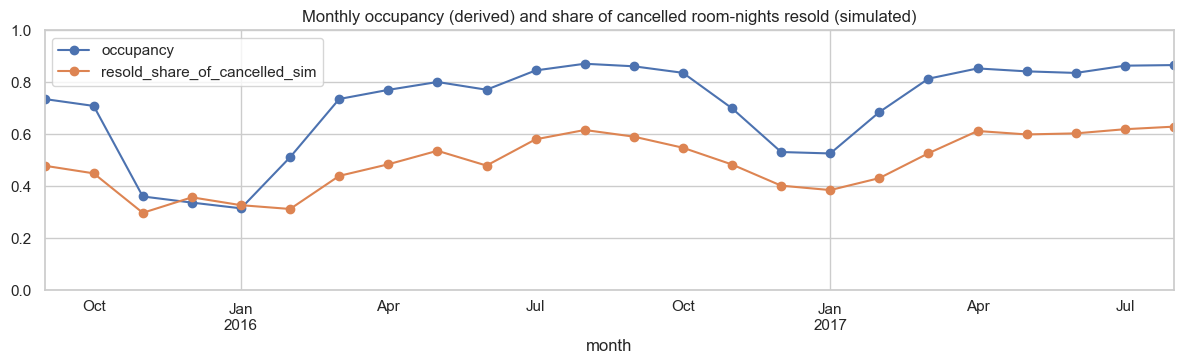

month,1,2,3,4,5,6,7,8,9,10,11,12
occupancy,0.420,0.599,0.775,0.812,0.822,0.804,0.855,0.869,0.799,0.773,0.530,0.434


room_type,A,B,C,D,E,F,G,K
occupancy,0.778,0.360,0.139,0.788,0.606,0.574,0.417,0.159


In [22]:
o = ops[~ops.is_partial_period & ops.available_rooms.gt(0)].copy()
o["month"] = o.stay_date.dt.to_period("M")
monthly = o.groupby("month")[["available_rooms", "rooms_sold", "rooms_cancelled", "resold_after_cancellation"]].sum()
monthly["occupancy"] = monthly.rooms_sold / monthly.available_rooms
monthly["resold_share_of_cancelled_sim"] = monthly.resold_after_cancellation / monthly.rooms_cancelled
fig, ax = plt.subplots(figsize=(12, 3.8))
monthly[["occupancy", "resold_share_of_cancelled_sim"]].plot(ax=ax, marker="o")
ax.set_ylim(0, 1); ax.set_title("Monthly occupancy (derived) and share of cancelled room-nights resold (simulated)")
plt.tight_layout(); plt.show()
cal = monthly.groupby(monthly.index.month)[["occupancy"]].mean().T            # calendar-month average, Sep-2015..Aug-2017
cal.columns.name = "month"
display(cal.round(3))
by_type = o.groupby("room_type")[["rooms_sold", "available_rooms"]].sum()
(by_type.rooms_sold / by_type.available_rooms).rename("occupancy").to_frame().T.round(3)

### 2.7 Group / block track: when and how blocks are released

For blocks, the key question is **when** rooms come back and **how many** at once, so the hotel can resell them or reallocate capacity.

,cancellations,median_days_notice,share_notice_30_plus,share_notice_0_7,share_in_batches_10_plus,resold_share_sim
population,,,,,,
group_block,16849,83.000,0.792,0.067,0.903,0.510
individual,15304,36.000,0.549,0.177,0.012,0.427


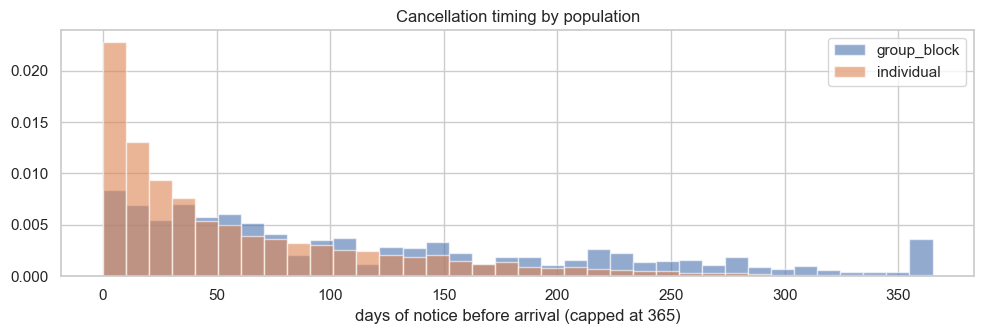

,bookings,cancel_rate
agent_id,,
1,7127,0.734
none,2831,0.672
6,2403,0.374
37,1226,0.584
3,1093,0.658
9,1070,0.635
19,1008,0.757
21,736,0.654


In [23]:
cc = df[df.reservation_status.astype(str) == "Canceled"].copy()
cc["days_notice"] = (cc.arrival_date - cc.reservation_status_date).dt.days
cc["batch_size"] = cc.groupby(["arrival_date", "reservation_status_date"]).booking_id.transform("size")
timing = cc.groupby("population").agg(
    cancellations=("booking_id", "size"),
    median_days_notice=("days_notice", "median"),
    share_notice_30_plus=("days_notice", lambda s: (s >= 30).mean()),
    share_notice_0_7=("days_notice", lambda s: (s <= 7).mean()),
    share_in_batches_10_plus=("batch_size", lambda s: (s >= 10).mean()),
    resold_share_sim=("syn_rebooking_revenue", lambda s: s.sum() / cc.loc[s.index, "gross_value"].sum()))
display(timing)
fig, ax = plt.subplots(figsize=(10, 3.5))
for p_, g_ in cc.groupby("population"):
    ax.hist(g_.days_notice.clip(upper=365), bins=36, alpha=0.6, density=True, label=p_)
ax.set_xlabel("days of notice before arrival (capped at 365)"); ax.set_title("Cancellation timing by population"); ax.legend()
plt.tight_layout(); plt.show()
gb = df[df.population == "group_block"]
display(gb.groupby("agent_id", observed=True).agg(bookings=("booking_id", "size"), cancel_rate=("is_canceled", "mean"))
          .sort_values("bookings", ascending=False).head(8))

### 2.8 Leakage check: features vs ops-only columns

In [24]:
leak = pd.DataFrame({
    "column": ["assigned_room_type != reserved", "country == PRT", "drv_arrival_occupancy", "syn_customer_response"],
    "cancel_rate_if_true_or_high": [
        df.loc[df.assigned_room_type.astype(str) != df.reserved_room_type.astype(str), "is_canceled"].mean(),
        df.loc[df.country.astype(str) == "PRT", "is_canceled"].mean(),
        df.loc[df.drv_arrival_occupancy >= df.drv_arrival_occupancy.quantile(.8), "is_canceled"].mean(),
        df.loc[df.syn_customer_response == "no_response", "is_canceled"].mean()],
    "why_excluded": ["final allocation; may change until check-in (timing unknown)",
                     "booking-time value not verified; strong outcome association; fairness",
                     "realised occupancy includes others' outcomes", "simulated from the outcome"],
})
leak["overall_rate"] = y.mean()
leak

,column,cancel_rate_if_true_or_high,why_excluded,overall_rate
0,assigned_room_type != reserved,0.059,final allocation; may change until check-in (t...,0.419
1,country == PRT,0.655,booking-time value not verified; strong outcom...,0.419
2,drv_arrival_occupancy,0.420,realised occupancy includes others' outcomes,0.419
3,syn_customer_response,0.339,simulated from the outcome,0.419


### 2.9 EDA findings

*(modelling population 78,892 bookings; train = arrivals to Dec 2016, test = Jan–Aug 2017; several findings below use 2017 labels, see the disclosure at the start of D2. All are associations, not causal effects.)*

1. **Two populations, two decisions.** The `group_block` **proxy** (26.2k bookings: segment Groups, Non Refund deposit, or ≥ 5 bookings with identical reservation attributes) cancels **64–67%**, early (median 83 days notice) and in batches (90% in batches of 10+). `individual` (52.7k) cancels **28% → 34%** (train → test), later (median 36 days) and one by one. Blocks need release deadlines, staged deposits and capacity reallocation; individuals need risk-based follow-up. The individual model is the headline model. The proxy is not a verified group label: 281 `Group` and 1,552 `Contract` bookings stay in `individual`. Under the alternative rules of Section 2.0.1, 91–98% of bookings keep the same label and the individual cancellation rate stays at 27.8–28.3% (train) and 33.9–34.8% (test).
2. **Strongest signals:** `deposit_type` (Cramér's V 0.52), `agent_id` (0.39), `market_segment` (0.29), `lead_time` (ρ +0.32), block size `dup_group_size` (+0.32) and special requests (−0.33). Within `individual` they are weaker and spread out (special requests −0.20, last-minute −0.20, log lead time +0.19), which is the realistic difficulty of the guest-level problem.
3. **Lead time × segment drives risk more than season.** Groups pass 50% from 31–90 days out (55%). Direct stays at or below 25% in every lead-time bin with at least 30 bookings (the > 365-day bin holds a single booking, which was cancelled). Monthly cancellation only varies between 37% (Mar) and 46% (Apr).
4. **Demand on the books at booking time** goes with lower risk (lowest OTB quintile 64% vs highest 32%), but mostly through lead time (ρ −0.57). Treat it as a secondary feature; it is a same-arrival-date count, not room-night inventory.
5. **Redundant pairs** (keep one for linear models): month ~ week (ρ 0.98), adults ~ total guests (0.89), total nights ~ week nights (0.80), segment ~ channel (V 0.75).
6. **Drift to handle at the model stage** (PSI on the union of categories, smoothed): agent mix changes most (PSI 1.09; 40 agent IDs appear only in 2017, covering 5.1% of test bookings), which supports the `agent_top` / `other` grouping. **Median ADR rises 16.5% (EUR 95.0 → 110.7; mean +18.8%, 99.3 → 118.0), train vs test**; part of this is the Jan–Aug season mix (ADR PSI 0.30). More Online TA / Transient (PSI 0.13–0.29). Previous-cancellation history collapses in 2017, almost only in `group_block` (PSI ≈ 1.9 there, ~0 for individuals).
7. **Leakage:** block size uses no outcome column, but it is a retrospective proxy from snapshot attributes whose booking-time availability is not verified. Room mismatch, `country`, realised arrival occupancy and all `syn_*` columns stay excluded. `booking_changes` counts changes **until check-in or cancellation**, so it is excluded from every model. Waiting list and special requests are day-before-arrival snapshots and are only allowed in the `pre_arrival` feature set (Section 3).
8. **Where the money is (simulated proxy).** On one contribution basis (Section 2.6), the simulated net loss proxy of cancelled bookings is about EUR 3.8M; Online TA carries ~58%, Groups ~19%, Offline TA/TO ~14%. The previous definition, which subtracted *gross* resale revenue from a contribution value, gave Online TA ~65% and understated Groups and Offline TA/TO. The split depends heavily on the deposit assumption: if Non Refund deposits were fully retained, Groups and Offline TA/TO would turn into net gains. These are scenario outputs, not a validated net loss. Calendar-month occupancy averages 77–87% from March to October vs 42–53% from November to January. **Hypothesis** for scenario analysis and a pilot: interventions and resale may be worth more in high season. This is not established: it depends on incremental response, resale opportunity and intervention cost, none of which is observed.

## 3. Feature engineering

**Scope and scoring contract.** This is a **retrospective prototype** built on a public PMS extract whose values were taken around the day before arrival. The dataset has no booking history, so the original value of a field at booking time cannot be reconstructed. Two time-aware feature sets are therefore defined, separately from the two populations:

| Feature set | Intended score time | Allowed inputs | Eligible bookings |
|---|---|---|---|
| `booking_time` (**primary**) | When the booking is entered | `numeric` + `categorical` lists | Every booking at entry |
| `pre_arrival` (secondary) | A fixed horizon before arrival (set in F1) | `booking_time` inputs + `pre_arrival_extra` (waiting list, special requests) | Only bookings **created and still active** (not cancelled) at score time; the filter is implemented in F1 |

- **Excluded from every model:** `booking_changes` / `has_booking_changes` (cumulative until check-in or cancellation), `otb_ratio_at_booking` and `room_type_capacity_share` (built from room capacity estimated with 2017 stays; redundant with `drv_otb_rooms_at_booking` and `reserved_room_type`).
- **Known limitation:** ADR, party size, meal, room type, segment and even the planned arrival date / lead time are the values in the extract, which may have changed after booking. Results describe a retrospective prototype; they do not prove performance of a live booking-time system.
- **Block-size proxy:** `dup_group_size`, its log, `is_group_block` and the `group_block` population rule are built from snapshot attributes of the whole booking-day cohort; their availability at booking entry is not verified. They are kept for the retrospective prototype. A strict booking-time experiment in F1 must drop or rebuild them **and** re-derive the population rule (dropping the columns from X alone is not enough).
- Train-only statistics (ADR reference, top-15 agents) are fitted on `split == "train"` and applied to both splits; F must refit them inside each validation fold.

In [25]:
fe = df.copy()
is_tr = fe.split == "train"

# --- lead time & booking timing
fe["lead_time_log"] = np.log1p(fe.lead_time)
fe["booking_month"] = fe.booking_date.dt.month
fe["booking_dow"] = fe.booking_date.dt.dayofweek
fe["is_last_minute"] = (fe.lead_time <= 7).astype(int)
fe["is_far_ahead"] = (fe.lead_time > 180).astype(int)

# --- arrival seasonality (cyclical encoding)
fe["arrival_month_sin"] = np.sin(2 * np.pi * fe.arrival_month_num / 12)
fe["arrival_month_cos"] = np.cos(2 * np.pi * fe.arrival_month_num / 12)
fe["arrival_week_sin"] = np.sin(2 * np.pi * fe.arrival_week_iso / 53)
fe["arrival_week_cos"] = np.cos(2 * np.pi * fe.arrival_week_iso / 53)
fe["is_weekend_arrival"] = fe.arrival_date.dt.dayofweek.isin([4, 5]).astype(int)
fe["is_high_season"] = fe.arrival_month_num.isin([4, 5, 6, 7, 8, 9, 10]).astype(int)

# --- stay & party
fe["weekend_night_share"] = (fe.stays_in_weekend_nights / fe.total_nights).fillna(0)
fe["is_long_stay"] = (fe.total_nights >= 7).astype(int)
fe["has_children"] = ((fe.children + fe.babies) > 0).astype(int)
fe["is_solo"] = (fe.total_guests == 1).astype(int)

# --- price (train-fitted reference: median ADR by reserved room type x arrival month)
ref = fe[is_tr & (fe.adr_clean > 0)].groupby(["reserved_room_type", "arrival_month_num"], observed=True).adr_clean.median()
ref_type = fe[is_tr & (fe.adr_clean > 0)].groupby("reserved_room_type", observed=True).adr_clean.median()
key = pd.MultiIndex.from_arrays([fe.reserved_room_type.astype(str), fe.arrival_month_num])
ref.index = ref.index.set_levels(ref.index.levels[0].astype(str), level=0)
base = pd.Series(ref.reindex(key).values, index=fe.index).fillna(fe.reserved_room_type.astype(str).map(ref_type.rename(index=str)))
# (the ADR data-error row is already excluded by exclude_from_model, so no imputation happens here)
assert fe.adr_clean.notna().all(), "unexpected missing ADR in the modelling population"
fe["adr_vs_ref"] = (fe.adr_clean / base).replace([np.inf, -np.inf], np.nan).fillna(1.0)
fe["adr_per_guest"] = fe.adr_clean / fe.total_guests.clip(lower=1)
fe["is_free_rate"] = (fe.adr_clean <= 0).astype(int)

# --- guest history & engagement
fe["prev_bookings_total"] = fe.previous_cancellations + fe.previous_bookings_not_canceled
fe["prev_cancel_ratio"] = (fe.previous_cancellations / fe.prev_bookings_total).fillna(0)
fe["has_prev_cancel"] = (fe.previous_cancellations > 0).astype(int)
fe["has_special_requests"] = (fe.total_of_special_requests > 0).astype(int)

# --- commercial
top_agents = fe[is_tr].agent_id.astype(str).value_counts().head(15).index
fe["agent_top"] = np.where(fe.agent_id.astype(str).isin(top_agents), fe.agent_id.astype(str), "other")
fe.loc[fe.agent_id.astype(str) == "none", "agent_top"] = "none"
fe["is_non_refund"] = (fe.deposit_type.astype(str) == "Non Refund").astype(int)
fe["is_group_block"] = (fe.dup_group_size >= 5).astype(int)
fe["dup_group_size_log"] = np.log1p(fe.dup_group_size)

# --- demand pressure at booking time: drv_otb_rooms_at_booking (Section 1.4) is used as is.
#     otb_ratio_at_booking / room_type_capacity_share are no longer built: their capacity denominator
#     came from realised stays including the 2017 test period.

# --- pre-arrival snapshot features (only for the pre_arrival feature set)
fe["has_waiting_list"] = (fe.days_in_waiting_list > 0).astype(int)
print("engineered features added")

engineered features added


In [26]:
NUMERIC_FEATURES = [
    "lead_time", "lead_time_log", "is_last_minute", "is_far_ahead", "booking_month", "booking_dow",
    "arrival_month_sin", "arrival_month_cos", "arrival_week_sin", "arrival_week_cos", "is_weekend_arrival", "is_high_season",
    "total_nights", "stays_in_weekend_nights", "stays_in_week_nights", "weekend_night_share", "is_long_stay",
    "adults", "children", "babies", "total_guests", "has_children", "is_solo",
    "adr_clean", "adr_vs_ref", "adr_per_guest", "is_free_rate",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled", "prev_bookings_total",
    "prev_cancel_ratio", "has_prev_cancel", "has_agent", "has_company",
    "drv_otb_rooms_at_booking",
]
# Day-before-arrival snapshot fields: only for the secondary pre_arrival feature set
PRE_ARRIVAL_EXTRA = ["days_in_waiting_list", "has_waiting_list", "total_of_special_requests", "has_special_requests"]
# Never used by any model (reason recorded in config)
EXCLUDED_FEATURES = {
    "booking_changes": "cumulative number of changes until check-in or cancellation -> future information",
    "has_booking_changes": "flag of booking_changes -> same future information",
    "otb_ratio_at_booking": "denominator = room capacity estimated from realised stays incl. 2017 test period; redundant with drv_otb_rooms_at_booking",
    "room_type_capacity_share": "capacity estimated from realised stays incl. 2017 test period; redundant with reserved_room_type",
}
CATEGORICAL_FEATURES = ["market_segment", "distribution_channel", "customer_type",
                        "reserved_room_type", "meal", "agent_top", "arrival_dow"]
# Only meaningful inside the group/block population
GROUP_ONLY_NUMERIC = ["is_non_refund", "is_group_block", "dup_group_size", "dup_group_size_log"]
GROUP_ONLY_CATEGORICAL = ["deposit_type"]
META = ["booking_id", "population", "split", "is_canceled", "arrival_date", "booking_date", "is_duplicate",
        "gross_value", "syn_net_booking_value"]           # not features: ids, population, target, split, business weights

feat = NUMERIC_FEATURES + PRE_ARRIVAL_EXTRA + CATEGORICAL_FEATURES + GROUP_ONLY_NUMERIC + GROUP_ONLY_CATEGORICAL
assert not set(feat) & set(EXCLUDED_FEATURES), set(feat) & set(EXCLUDED_FEATURES)
forbidden = set(GROUPS["ops_only_cols"]) | {c for c in fe.columns if c.startswith("syn_")} | {"drv_arrival_occupancy"}
assert not set(feat) & forbidden, set(feat) & forbidden
assert fe[feat].isna().sum().sum() == 0, fe[feat].isna().sum()[lambda s: s > 0]

modeling = fe[META + feat].copy()
modeling.round({c: 4 for c in modeling.select_dtypes("float").columns}).to_csv(PROC / "modeling_dataset.csv", index=False, date_format="%Y-%m-%d")

for k in ["modeling_numeric", "modeling_caveat", "modeling_categorical", "model_features"]:
    GROUPS.pop(k, None)
GROUPS.update({
    "population_rule": "group_block if market_segment == Groups OR deposit_type == Non Refund OR dup_group_size >= 5; else individual",
    "population_note": "group_block is an inferred proxy, not a verified group label (customer_type is not used). dup_group_size comes from "
                       "snapshot attributes of the booking-day cohort; its booking-time availability is not verified. A strict booking-time "
                       "experiment must drop/rebuild the block-size features AND re-derive this rule. Sensitivity: notebook 03, Section 2.0.1.",
    "individual_model": {"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES,
                         "pre_arrival_extra": PRE_ARRIVAL_EXTRA},
    "group_model": {"numeric": NUMERIC_FEATURES + GROUP_ONLY_NUMERIC,
                    "categorical": CATEGORICAL_FEATURES + GROUP_ONLY_CATEGORICAL, "pre_arrival_extra": PRE_ARRIVAL_EXTRA},
    "feature_sets": {
        "booking_time": "PRIMARY. numeric + categorical of the population. Score time = booking entry; every booking eligible.",
        "pre_arrival": "SECONDARY. booking_time inputs + pre_arrival_extra. Score time = fixed horizon before arrival (set in F1); "
                       "only bookings created and still active (not cancelled) at score time are eligible (filter implemented in F1).",
    },
    "excluded_features": EXCLUDED_FEATURES,
    "scope_note": "Retrospective prototype: field values come from a near-arrival PMS snapshot; ADR and other mutable fields "
                  "may differ from their booking-time values. modeling_dataset.csv is already filtered to exclude_from_model == False "
                  "(data-quality filter only); the pre_arrival eligibility filter (created and still active at score time) is applied in F1.",
    "test_note": "EDA (notebook 03, sections 2.0-2.3, 2.6-2.8) used 2017 labels: the 2017 test set is a partially explored holdout. "
                 "Choose thresholds / tune on a validation period inside the training years.",
    "modeling_meta": META,
    "split_rule": f"train: arrival_date <= {TRAIN_END.date()} | test: after",
})
json.dump(GROUPS, open(CFG / "column_groups.json", "w"), indent=2)

print("Saved:", PROC / "modeling_dataset.csv", modeling.shape)
print(f"individual model: {len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical (booking_time) "
      f"+ {len(PRE_ARRIVAL_EXTRA)} pre_arrival_extra")
print(f"group model     : + {len(GROUP_ONLY_NUMERIC)} numeric + {len(GROUP_ONLY_CATEGORICAL)} categorical (block / deposit)")
modeling.groupby(["population", "split"]).agg(rows=("booking_id", "size"), cancel_rate=("is_canceled", "mean"),
                              first_arrival=("arrival_date", "min"), last_arrival=("arrival_date", "max"))

Saved: C:\Users\ADMIN\Desktop\AAA\BA-Advance-Project---Group-2-main\data\processed\modeling_dataset.csv (78892, 61)
individual model: 36 numeric + 7 categorical (booking_time) + 4 pre_arrival_extra
group model     : + 4 numeric + 1 categorical (block / deposit)


rows  cancel_rate first_arrival last_arrival
population  split                                               
group_block test    6997        0.667    2017-01-01   2017-08-31
            train  19219        0.642    2015-07-01   2016-12-30
individual  test   20399        0.344    2017-01-01   2017-08-31
            train  32277        0.280    2015-07-01   2016-12-31

### 3.1 Quick check of the engineered features

In [27]:
new_feats = ["lead_time_log", "adr_vs_ref", "prev_cancel_ratio", "is_non_refund", "is_group_block",
             "drv_otb_rooms_at_booking", "has_special_requests", "weekend_night_share", "is_last_minute", "is_far_ahead"]
rows = []
for p_ in ["individual", "group_block"]:
    m_ = modeling[modeling.population == p_]
    trm, tsm = m_[m_.split == "train"], m_[m_.split == "test"]
    for c in new_feats:
        if p_ == "individual" and c in GROUP_ONLY_NUMERIC:
            continue
        rows.append({"population": p_, "feature": c,
                     "spearman_with_target": trm[c].corr(trm.is_canceled, method="spearman"),
                     "psi_train_vs_test": psi(trm[c], tsm[c])})
chk = pd.DataFrame(rows).pivot(index="feature", columns="population")
chk.sort_values(("spearman_with_target", "individual"), key=abs, ascending=False).round(3)

spearman_with_target            psi_train_vs_test           
population                        group_block individual       group_block individual
feature                                                                              
has_special_requests                   -0.378     -0.200             0.084      0.003
is_last_minute                         -0.117     -0.197             0.009      0.052
lead_time_log                           0.313      0.192             0.521      0.138
prev_cancel_ratio                       0.407      0.166             1.897      0.000
adr_vs_ref                             -0.059      0.075             1.269      0.284
is_far_ahead                            0.242      0.067             0.067      0.058
drv_otb_rooms_at_booking               -0.242     -0.060             0.428      0.011
weekend_night_share                    -0.023      0.003             0.035      0.007
is_group_block                          0.131        NaN             0.009        NaN
is_non_refund                           0.700        NaN             0.022        NaN

**Feature engineering notes:**
- `modeling_dataset.csv`: 78,892 rows with `population` and `split`, already filtered to `exclude_from_model == False` (data-quality filter only; the `pre_arrival` eligibility filter is applied in F1). **Individual model (`booking_time`, primary):** 36 numeric + 7 categorical; `pre_arrival` adds 4 snapshot features. **Group model:** the same plus block / deposit features (`is_non_refund` ρ 0.70, so rules or a simple model are enough; the value is forecasting *when and how many* rooms return).
- Train-only fitting: ADR reference (room type × month) and top-15 agents. Categoricals are left for the sklearn pipeline.
- Watch-outs: `adr_vs_ref` drifts (PSI 0.28 individual); in `group_block`, history, lead time and OTB features drift strongly.
- Feature lists: `config/column_groups.json` → `individual_model`, `group_model`, `feature_sets`, `excluded_features`. Meaning, lineage and availability time of every feature: `docs/feature_availability.csv` (Section 3.2).
- `group_block` is an inferred **proxy** for block/allotment bookings, not a verified group label (281 `Group` and 1,552 `Contract` bookings stay in `individual`; Section 2.0.1). `dup_group_size` is a retrospective group size computed from snapshot attributes; its availability at booking entry or at the end of the booking day is **not verified**.

### 3.2 Feature availability register

One row per model feature: meaning, source and lineage, when the business would need it, when it is actually present in this dataset, whether it is fitted on the training period, and which populations / feature sets may use it. Exported to `docs/feature_availability.csv`. "Booking time" in `business_need` is when the business **would need** the value; it does **not** mean the dataset holds the booking-time value: see `in_dataset_as`. The provenance convention matches `docs/data_dictionary.csv` (`source` = REAL for an original PMS column used as is, DERIVED for anything computed, including cleaned values such as `adr_clean`).

In [28]:
SNAP = "near-arrival snapshot (value may have changed after booking)"
CAL = "deterministic calendar transform of the snapshot arrival date (and lead_time); not proof the date was unchanged since booking"
BLOCK = "retrospective group size from snapshot attributes; availability at booking entry or end of booking day is not verified"
F = {  # feature: (meaning, source, lineage, in_dataset_as, fit_on_train)
    "lead_time": ("Days from booking entry to planned arrival", "REAL", "lead_time",
                  "as last recorded in the near-arrival snapshot (a revised arrival date would change it)", "no"),
    "lead_time_log": ("log(1 + lead_time)", "DERIVED", "lead_time", SNAP, "no"),
    "is_last_minute": ("lead_time <= 7", "DERIVED", "lead_time", SNAP, "no"),
    "is_far_ahead": ("lead_time > 180", "DERIVED", "lead_time", SNAP, "no"),
    "booking_month": ("Month of booking_date", "DERIVED", "arrival_date - lead_time", CAL, "no"),
    "booking_dow": ("Weekday of booking_date (0 = Monday)", "DERIVED", "arrival_date - lead_time", CAL, "no"),
    "arrival_month_sin": ("Cyclical arrival month (sine)", "DERIVED", "arrival_month_num", CAL, "no"),
    "arrival_month_cos": ("Cyclical arrival month (cosine)", "DERIVED", "arrival_month_num", CAL, "no"),
    "arrival_week_sin": ("Cyclical ISO arrival week (sine)", "DERIVED", "arrival_week_iso", CAL, "no"),
    "arrival_week_cos": ("Cyclical ISO arrival week (cosine)", "DERIVED", "arrival_week_iso", CAL, "no"),
    "is_weekend_arrival": ("Arrival on Friday or Saturday", "DERIVED", "arrival_date", CAL, "no"),
    "is_high_season": ("Arrival in April-October", "DERIVED", "arrival_month_num", CAL, "no"),
    "total_nights": ("Booked nights", "DERIVED", "weekend + week nights", SNAP, "no"),
    "stays_in_weekend_nights": ("Booked weekend nights", "REAL", "stays_in_weekend_nights", SNAP, "no"),
    "stays_in_week_nights": ("Booked week nights", "REAL", "stays_in_week_nights", SNAP, "no"),
    "weekend_night_share": ("Weekend nights / total nights", "DERIVED", "stay nights", SNAP, "no"),
    "is_long_stay": ("total_nights >= 7", "DERIVED", "total_nights", SNAP, "no"),
    "adults": ("Number of adults", "REAL", "adults", SNAP, "no"),
    "children": ("Number of children (4 NaN -> 0)", "REAL", "children", SNAP, "no"),
    "babies": ("Number of babies", "REAL", "babies", SNAP, "no"),
    "total_guests": ("adults + children + babies", "DERIVED", "party size", SNAP, "no"),
    "has_children": ("children + babies > 0", "DERIVED", "party size", SNAP, "no"),
    "is_solo": ("total_guests == 1", "DERIVED", "party size", SNAP, "no"),
    "adr_clean": ("Average daily rate, EUR (data error removed)", "DERIVED", "raw REAL adr; the EUR 5,400 error set to NULL (row excluded)",
                  SNAP + "; transaction-derived, the rate quoted at booking is not available", "no"),
    "adr_vs_ref": ("ADR / train median ADR of (room type, arrival month)", "DERIVED", "adr_clean, reference fitted on train", SNAP, "yes (reference medians)"),
    "adr_per_guest": ("ADR / total_guests", "DERIVED", "adr_clean, total_guests", SNAP, "no"),
    "is_free_rate": ("ADR <= 0", "DERIVED", "adr_clean", SNAP, "no"),
    "is_repeated_guest": ("Guest stayed before", "REAL", "is_repeated_guest", SNAP, "no"),
    "previous_cancellations": ("Guest's earlier cancelled bookings", "REAL", "previous_cancellations", SNAP, "no"),
    "previous_bookings_not_canceled": ("Guest's earlier kept bookings", "REAL", "previous_bookings_not_canceled", SNAP, "no"),
    "prev_bookings_total": ("Sum of the two history counts", "DERIVED", "history counts", SNAP, "no"),
    "prev_cancel_ratio": ("previous_cancellations / prev_bookings_total (0 if none)", "DERIVED", "history counts", SNAP, "no"),
    "has_prev_cancel": ("previous_cancellations > 0", "DERIVED", "history counts", SNAP, "no"),
    "has_agent": ("Booked through a travel agent", "DERIVED", "agent not null", SNAP, "no"),
    "has_company": ("A company pays", "DERIVED", "company not null", SNAP, "no"),
    "drv_otb_rooms_at_booking": ("Earlier bookings for the same arrival date still active on this booking's booking date (same-arrival-date count, all room types; not room-night inventory)", "DERIVED", "booking_date, reservation_status, reservation_status_date of OTHER bookings", "reconstructed as of the booking date from other bookings' snapshot dates (day granularity, within-day order unknown)", "no"),
    "market_segment": ("Market segment", "REAL", "market_segment", SNAP, "no"),
    "distribution_channel": ("Distribution channel", "REAL", "distribution_channel", SNAP, "no"),
    "customer_type": ("Transient / Transient-Party / Contract / Group", "REAL", "customer_type", SNAP, "no"),
    "reserved_room_type": ("Reserved room type", "REAL", "reserved_room_type", SNAP, "no"),
    "meal": ("Meal package", "REAL", "meal (Undefined -> SC)", SNAP, "no"),
    "agent_top": ("Agent ID if among the 15 most frequent in train, else 'other' / 'none'", "DERIVED", "agent_id, top list fitted on train", SNAP, "yes (top-15 list)"),
    "arrival_dow": ("Weekday of arrival", "DERIVED", "arrival_date", CAL, "no"),
    "days_in_waiting_list": ("Days on the waiting list before confirmation", "REAL", "days_in_waiting_list", SNAP + "; completed duration", "no"),
    "has_waiting_list": ("days_in_waiting_list > 0", "DERIVED", "days_in_waiting_list", SNAP, "no"),
    "total_of_special_requests": ("Number of special requests (can be added after booking)", "REAL", "total_of_special_requests", SNAP, "no"),
    "has_special_requests": ("total_of_special_requests > 0", "DERIVED", "total_of_special_requests", SNAP, "no"),
    "is_non_refund": ("deposit_type == Non Refund", "DERIVED", "deposit_type", SNAP, "no"),
    "is_group_block": ("dup_group_size >= 5", "DERIVED", "dup_group_size", BLOCK, "no"),
    "dup_group_size": ("Bookings sharing the same 21 reservation attributes in the extract (block-size proxy, not a verified group ID)", "DERIVED",
                       "21 reservation columns from the snapshot, no outcome column", BLOCK, "no"),
    "dup_group_size_log": ("log(1 + dup_group_size)", "DERIVED", "dup_group_size", BLOCK, "no"),
    "deposit_type": ("Deposit condition", "REAL", "deposit_type", SNAP, "no"),
}
fa = []
for pop_key, pop in [("individual_model", "individual"), ("group_model", "group_block")]:
    g = GROUPS[pop_key]
    for kind in ["numeric", "categorical", "pre_arrival_extra"]:
        for c in g[kind]:
            m = F[c]
            fa.append({"feature": c, "population": pop, "dtype": "categorical" if kind == "categorical" else "numeric",
                       "feature_set": "pre_arrival only" if kind == "pre_arrival_extra" else "booking_time + pre_arrival",
                       "meaning": m[0], "source": m[1], "lineage": m[2],
                       "business_need": "pre-arrival horizon" if kind == "pre_arrival_extra" else "booking time",
                       "in_dataset_as": m[3], "fit_on_train": m[4]})
fa = (pd.DataFrame(fa).groupby("feature", sort=False)
        .agg({**{k: "first" for k in ["dtype", "feature_set", "meaning", "source", "lineage", "business_need", "in_dataset_as", "fit_on_train"]},
              "population": lambda s: " + ".join(s)}).reset_index())
for c, why in GROUPS["excluded_features"].items():
    fa.loc[len(fa)] = {"feature": c, "population": "none", "dtype": "numeric", "feature_set": "EXCLUDED",
                       "meaning": why, "source": "REAL" if c == "booking_changes" else "DERIVED", "lineage": "",
                       "business_need": "", "in_dataset_as": "", "fit_on_train": ""}
used = set(fa.loc[fa.feature_set != "EXCLUDED", "feature"])
assert used == set(feat), set(feat) ^ used
(ROOT / "docs").mkdir(exist_ok=True)
fa.to_csv(ROOT / "docs" / "feature_availability.csv", index=False)
print(f"Saved: docs/feature_availability.csv ({len(fa)} rows: {len(used)} model features + {len(GROUPS['excluded_features'])} excluded)")
fa.groupby(["feature_set", "population"]).size().rename("features").to_frame()

Saved: docs/feature_availability.csv (56 rows: 52 model features + 4 excluded)


features
feature_set                population                        
EXCLUDED                   none                             4
booking_time + pre_arrival group_block                      5
                           individual + group_block        43
pre_arrival only           individual + group_block         4

### 3.3 Timeline facts for F1 (model-fit date, score date, label maturity)

The arrival-based split is a retrospective **arrival-cohort** evaluation, not a point-in-time backtest. Two facts that the F1 validation design must handle (see `docs/F1_validation_design.md`):
- many 2017-arrival (test) bookings were **created before** the training cutoff, so a model fitted at year-end 2016 could not have scored them at their booking date;
- some training rows have a final status date after the cutoff. For a **Check-Out**, that date is the check-out day. Under the label-known convention used here (Check-Out / No-Show → arrival date), the label is settled on the arrival day, so a later status date does **not** by itself mean the label was unknown. The extract has no log of when check-in / no-show was actually recorded, so "0 unknown labels" holds **by this convention**, not as a verified system fact;
- for the `pre_arrival` set, the score date is `arrival_date − H`. For arrivals early in an evaluation window, that date falls **on or before** the model-fit date, so a model fitted at the cutoff would be scoring the past. F1 therefore fits each `pre_arrival` model at window start − H − 1 day, so every score date is after the fit date. The sensitivity check keeps the old cutoff (the day **before** the window starts) and excludes these bookings (`docs/F1_validation_design.md`, Section 5). The table below counts them against that old cutoff.

In [29]:
tl = df[["population", "split", "booking_date", "arrival_date", "reservation_status", "reservation_status_date"]].copy()
# when is the binary label settled? Canceled -> cancellation date; Check-Out / No-Show -> arrival date (guest came or not)
tl["label_known_date"] = np.where(tl.reservation_status.astype(str).eq("Canceled"), tl.reservation_status_date, tl.arrival_date)
tl["label_known_date"] = pd.to_datetime(tl.label_known_date)
test_booked_before = tl[tl.split.eq("test") & (tl.booking_date <= TRAIN_END)]
train_status_after = tl[tl.split.eq("train") & (tl.reservation_status_date > TRAIN_END)]
print(f"Test bookings (arrival 2017) created on or before {TRAIN_END.date()}: {len(test_booked_before):,} "
      f"of {tl.split.eq('test').sum():,} ({len(test_booked_before) / tl.split.eq('test').sum():.1%})")
display(test_booked_before.groupby("population").size().rename("bookings").to_frame())
print(f"Train rows whose final status date is after {TRAIN_END.date()}: {len(train_status_after):,}")
display(train_status_after.reservation_status.astype(str).value_counts().rename("rows").to_frame())
print(f"... of which the label is settled after the cutoff (label-known convention): {(train_status_after.label_known_date > TRAIN_END).sum():,}")

# pre_arrival: eligible bookings (created on or before the score date and still active then) whose score date is on or
# before the old cutoff of their window (the day before the window starts). Primary F1 rule: fit at window start - H - 1 day,
# so none of them is scored before its model's fit date; excluding them is only the sensitivity variant.
WINDOWS = {  # evaluation window: (old cutoff = day before the window, first arrival, last arrival)
    "fold 1": ("2016-03-31", "2016-04-01", "2016-06-30"), "fold 2": ("2016-06-30", "2016-07-01", "2016-09-30"),
    "fold 3": ("2016-09-30", "2016-10-01", "2016-12-31"), "test": (str(TRAIN_END.date()), "2017-01-01", "2017-08-31")}
pre = []
for H in (14, 30):
    s_date = tl.arrival_date - pd.Timedelta(days=H)
    eligible = (tl.booking_date <= s_date) & ~(tl.reservation_status.astype(str).eq("Canceled") & (tl.reservation_status_date <= s_date))
    for w, (fit, a0, a1) in WINDOWS.items():
        in_w = tl.arrival_date.between(a0, a1) & eligible
        primary_fit = pd.Timestamp(a0) - pd.Timedelta(days=H + 1)          # primary rule: window start - H - 1 day
        pre.append({"H_days": H, "window": w, "old_cutoff": fit, "eligible": int(in_w.sum()),
                    "score_on_or_before_old_cutoff": int((in_w & (s_date <= pd.Timestamp(fit))).sum()),
                    "primary_fit_date": str(primary_fit.date()),
                    "score_on_or_before_primary_fit": int((in_w & (s_date <= primary_fit)).sum())})
pre = pd.DataFrame(pre).set_index(["H_days", "window"])
assert (pre.score_on_or_before_primary_fit == 0).all()
pre


Test bookings (arrival 2017) created on or before 2016-12-31: 9,946 of 27,396 (36.3%)


,bookings
population,
group_block,4671
individual,5275


Train rows whose final status date is after 2016-12-31: 218


,rows
reservation_status,
Check-Out,218


... of which the label is settled after the cutoff (label-known convention): 0


old_cutoff  eligible  score_on_or_before_old_cutoff primary_fit_date  score_on_or_before_primary_fit
H_days window                                                                                                      
14     fold 1  2016-03-31      5581                            807       2016-03-17                               0
       fold 2  2016-06-30      5732                            806       2016-06-16                               0
       fold 3  2016-09-30      4645                           1025       2016-09-16                               0
       test    2016-12-31     13474                            408       2016-12-17                               0
30     fold 1  2016-03-31      5132                           1646       2016-03-01                               0
       fold 2  2016-06-30      5370                           1768       2016-05-31                               0
       fold 3  2016-09-30      4179                           1915       2016-08-31                               0
       test    2016-12-31     12194                            664       2016-12-01                               0